In [3]:
#%pip install pipreqs

#!python -m venv venv
#!venv\Scripts\python.exe -m pip install pipreqs
#!venv/Scripts/pipreqs.exe .

In [8]:

%pip install tensorflow

^C
Note: you may need to restart the kernel to use updated packages.


## Inicialização 

In [17]:
# Importando as livrarias genéricas
import pandas as pd
import matplotlib.pyplot as plt
import os
import inspect
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Importando as livrarias específicas
import tensorflow.keras.preprocessing.image

## Carregue os dados

O conjunto de dados é armazenado na pasta `/data/faces/`, onde você pode encontrar "
- A pasta `final_files` com 7,6k fotos "
- O arquivo `labels.csv` com rótulos, com duas colunas: `file_name` e `real_age` 

Dado que o número de arquivos de imagem é bastante alto, é aconselhável evitar a leitura de todos de uma vez, o que consumiria muito recursos computacionais. Recomendamos que você crie um gerador com o ImageDataGenerator. 

O arquivo de rótulo pode ser carregado como um arquivo CSV normal.

In [ ]:
# Carregando os dados
path_csv = os.path.join('data/faces', 'labels.csv')
DATASET_PATH = 'data/faces'
df_rot = pd.read_csv(path_csv)

# Verificação básica 
print(f"Formato dos dados : \n{df_rot.shape}")
print(f"Listagem das primeiras 5 linhas:\n{df_rot.head()}")

Formato dos dados : 
(7591, 2)
Listagem das primeiras 5 linhas:
    file_name  real_age
0  000000.jpg         4
1  000001.jpg        18
2  000002.jpg        80
3  000003.jpg        50
4  000004.jpg        17


## EDA

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB
############################################################
Estatística da coluna 'real_age' do dataset:
          real_age
count  7591.000000
mean     31.201159
std      17.145060
min       1.000000
25%      20.000000
50%      29.000000
75%      41.000000
max     100.000000
########################################
Percentagem de fotos > 60 anos: 5.88%
Percentagem de fotos idades vizinhas do limite: 7.26%


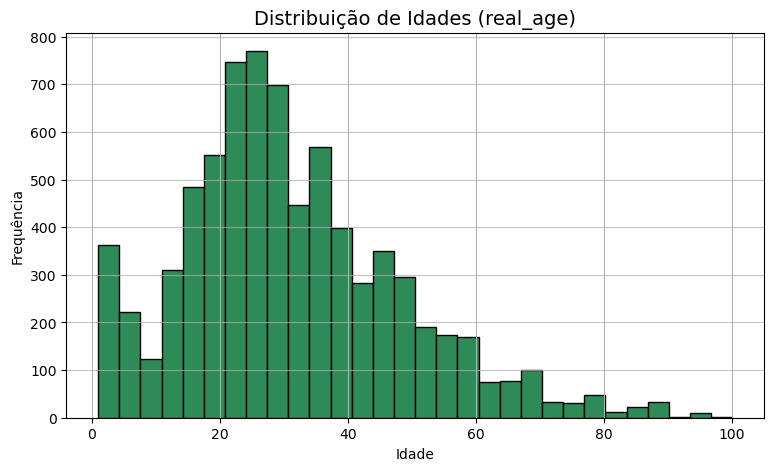

Found 15 validated image filenames.


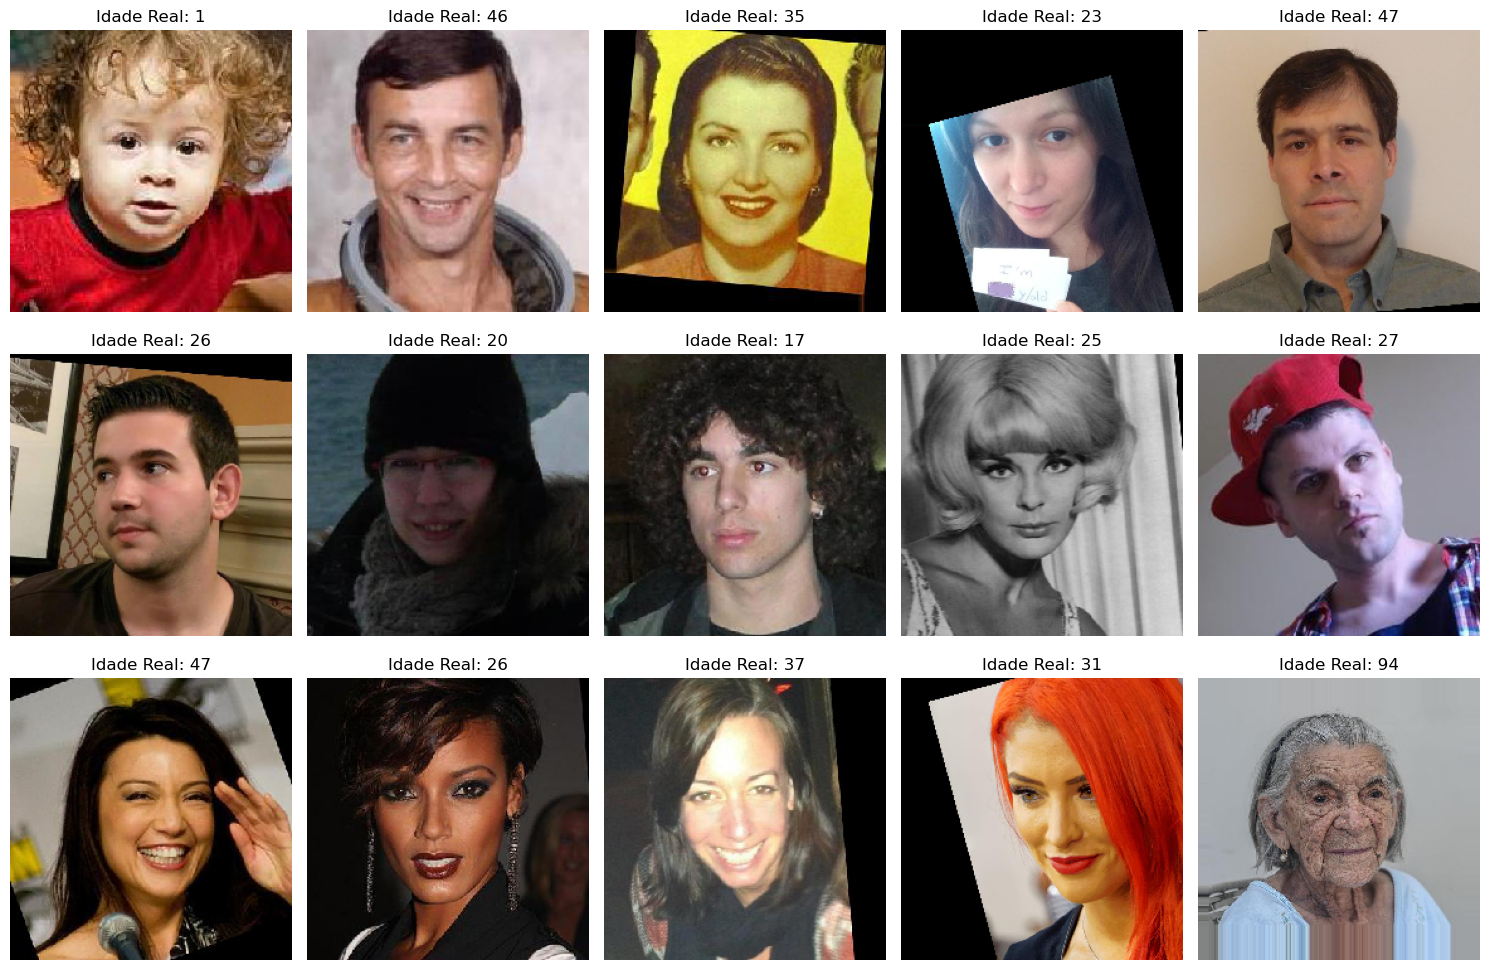

In [8]:
# Explorando a tabela de rótulos 
df_rot.info() # Informações gerais do dataset
print("#"*60)
print(f"Estatística da coluna 'real_age' do dataset:\n{df_rot.describe()}")
#######################################
# Calculando percentagens
fotos_maiores_60 = len(df_rot[df_rot['real_age'] > 60]) #Filtrando e contando as fotos com idades maior que 60
fotos_idade_limite = len(df_rot[(df_rot['real_age'] >= 18) & (df_rot['real_age'] <= 20)]) # Encontrar as idades vizinhas da idade limite

total_fotos = len(df_rot) # Contado o total de fotos no df

percent = (fotos_maiores_60 / total_fotos) * 100
percent_viz = (fotos_idade_limite / total_fotos) * 100
print('#'*40)
print(f"Percentagem de fotos > 60 anos: {percent:.2f}%")
print(f"Percentagem de fotos idades vizinhas do limite: {percent_viz:.2f}%")
print("="*100)

#######################################
# Criação de histograma de distribuição das idades
df_rot['real_age'].hist(bins=30, color='seagreen', edgecolor='black', figsize=(9, 5))

plt.title('Distribuição de Idades (real_age)', fontsize=14)
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=0.75) # Mantendo apenas as linhas hosizontais de grade

plt.show()

# Visualização de amostra de imagens
path_imagens = os.path.join(DATASET_PATH, 'final_files/')

df_sample = df_rot.sample(n=15, random_state=42).reset_index(drop=True) # Selecionando apenas 15 imagens 

datagen = ImageDataGenerator(rescale=1.0 / 255) # Criando o gerador limpo, apenas aplicando o rescale para o matplotlib 

generator = datagen.flow_from_dataframe(
    dataframe=df_sample,
    directory=path_imagens,
    x_col="file_name",
    y_col="real_age",
    target_size=(224, 224),
    batch_size=15,
    class_mode="raw",
    shuffle=False, # Manter paread com a ordem do df_rot
)
images_batch, ages_batch = next(generator) # Captura do lote de 15 imagens e idades

# Renderizando o grid 3x5
fig, axes = plt.subplots(3, 5, figsize=(15, 10))
axes = axes.ravel()

for i in range(15):
    batch = next(generator, (None, None))
    if batch[0] is None or len(batch[0]) == 0:
        raise ValueError("Gerador vazio: verifique o caminho das imagens e o campo `file_name`.")

    images_batch, ages_batch = batch

    for i in range(len(images_batch)):
        axes[i].imshow(images_batch[i])
        axes[i].set_title(f"Idade Real: {int(ages_batch[i])}")
        axes[i].axis("off")
    axes[i].set_title(f"Idade Real: {int(ages_batch[i])}")
    axes[i].axis("off")
    
plt.tight_layout()
plt.show()

### Conclusões

- Este dataset possui 7591 linhas e 2 colunas;
- Olhando para o histograma, nota-se claramente que a distribuição de idades não é equilibrada: A faixa dos idosos, é claramente sub-representada;
- A faixa dos idosos (>60 anos) que aparece com problema de sub-representação, representa 5.88% das fotos totais;
- É importante frisar também que no intervalo de idades entre 0 - 20 existem pelo menos 3 picos significativos até os 5 e depois um pouco antes dos 20 anos, a faixa em questão é bem próxima do limite de idade para a aquisição de álcool, com 7.26% das fotos estando localizadas entre os 18 e os 20 anos;
- A faixa de 20 - 40, aparece como a faixa mais bem representada em termos de frequência;
- Analisando as imagens consegue-se observar que, algumas imagens podem se tornar um desafio para o modelo aprender porque: possuem pouca iluminosidade, estão com um ângulo um pouco complicado, parte do cabelo cobre parte importante do rosto, e possui parcialmente caras de outros intervenientes na mesma foto;
- Isto sugere que o modelo poderá ter maior dificuldades a generalizar para a faixa de idosos, porque uma sub-representação pode ter um impacto negativo nos resultados finais.

## Modelagem 

Defina as funções necessárias para treinar seu modelo na plataforma GPU e construa um único script contendo todas elas junto com a seção de inicialização.

Para facilitar essa tarefa, você pode defini-las neste notebook e executar um código pronto na próxima seção para compor o script automaticamente.
As definições abaixo também serão verificadas pelos revisores do projeto, para que possam entender como você construiu o modelo.

In [9]:
import pandas as pd
import os

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.optimizers import Adam

In [12]:
def load_train(path):
    
    """
    Carrega a parte de treinamento do conjunto de dados a partir do caminho
    """
    path_csv = os.path.join(path, 'labels.csv')
    df_rot = pd.read_csv(path_csv)
    
    path_imagens = os.path.join(path, 'final_files/')

    # Inicializando o gerador com a validação split e scaling
    train_datagen = ImageDataGenerator(
        rescale=1.0 / 255,
        validation_split=0.20, # Reservando 20% dos dados para validação
        horizontal_flip=True, # Aplicando flip horizontal para aumentar a diversidade do dataset
    )
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=df_rot,
        directory=path_imagens,
        x_col="file_name",
        y_col="real_age",
        target_size=(224, 224),
        batch_size=32,
        class_mode="raw",
        subset="training", # Especificando este ponto como sendo a pool de trainamento
        seed=12345,
    
    )

    return train_gen_flow

In [13]:
def load_test(path):
    
    """
    Carrega a parte de validação/teste do conjunto de dados a partir do caminho
    """
    path_csv = os.path.join(path, 'labels.csv')
    df_rot = pd.read_csv(path_csv)

    path_imagens = os.path.join(path, 'final_files/')    
    
    # Inicializando o gerador com validação split e scaling
    test_datagen = ImageDataGenerator(rescale=1.0 / 255, validation_split=0.20)
    
    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=df_rot,
        directory=path_imagens,
        x_col="file_name",
        y_col="real_age",
        target_size=(224, 224),
        batch_size=32,
        class_mode="raw",
        subset="validation",
        seed=12345,
    
    )
    return test_gen_flow

In [14]:
def create_model(input_shape):
    
    """
   Define o modelo
    """
    
   # Model sequential
    model = Sequential()
    # Adicionando a ResNet50 pré-treinada
    model.add(
        ResNet50(
            input_shape=input_shape, include_top=False, weights="imagenet"
        
        )
    
    )
    model.add(GlobalAveragePooling2D()) # Redução de dimensionalidade (flat vector)
    model.add(Dense(1, activation="linear")) # Output layer para regressão
    
    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss="mean_squared_error",
        metrics=["mae"],
    
    )
    return model

In [16]:
def train_model(model, train_data, test_data, batch_size=None, epochs=20,
                steps_per_epoch=None, validation_steps=None):

    """
    Treina o modelo de acordo com os parâmetros
    """
    
    history = model.fit(
        x=train_data,
        validation_data=test_data,
        epochs=epochs,
        batch_size=batch_size,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        verbose=2
    )

    return model

## Preparar o Script para a Execução na plataforma GPU

Dado que você definiu as funções necessárias, você pode compor um script para a plataforma GPU, baixá-lo através do menu "Arquivo|Abrir..." e carregá-lo posteriormente para execução na plataforma GPU.

Nota: O script também deve incluir a seção de inicialização. Um exemplo disso é mostrado abaixo.

In [ ]:
# preparar um script para ser executado na plataforma GPU


init_str = """
import pandas as pd
import os

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.optimizers import Adam
"""

# Bloco de execução
execution_str = """
if __name__ == "__main__":
    path = "/datasets/faces"
    
    # 1. Carrega os dados de treino e teste
    train_data = load_train(path)
    test_data = load_test(path)
    
    # 2. Inicializa a arquitetura passando o input_shape correto
    model = create_model(input_shape=(224, 224, 3))
    
    # 3. Executa o treinamento do modelo
    train_model(model, train_data, test_data, epochs=20)
"""

with open('run_model_on_gpu.py', 'w') as f:
    
    f.write(init_str)
    f.write('\n\n')
        
    for fn_name in [load_train, load_test, create_model, train_model]:
        
        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

    f.write(execution_str)
    
print("Script 'run_model_on_gpu.py' pronto com todas as funções e fluxo de execução!")

Script 'run_model_on_gpu.py' pronto com todas as funções e fluxo de execução!


### Resultado

```
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1793010313.451150   57640 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793010313.522881   57640 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1793010315.984992   57640 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Found 6073 validated image filenames.
Found 1518 validated image filenames.
W0000 00:00:1793010319.644302   57640 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1793010319.645910   57640 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20833 MB memory:  -> device: 0, name: NVIDIA L4, pci bus id: 0000:00:03.0, compute capability: 8.9
Epoch 1/20
I0000 00:00:1793010322.178869   57640 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793010351.279753   57753 service.cc:153] XLA service 0x7ad2bc0535c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793010351.279786   57753 service.cc:161]   StreamExecutor [0]: NVIDIA L4, Compute Capability 8.9 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793010352.155845   57753 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793010357.036283   57753 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793010387.861165   57753 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
190/190 - 140s - 738ms/step - loss: 214.3362 - mae: 10.5624 - val_loss: 936.9323 - val_mae: 25.7101
Epoch 2/20
190/190 - 32s - 166ms/step - loss: 65.8082 - mae: 6.2007 - val_loss: 442.1972 - val_mae: 15.7888
Epoch 3/20
190/190 - 32s - 167ms/step - loss: 36.5713 - mae: 4.6496 - val_loss: 338.0045 - val_mae: 13.8452
Epoch 4/20
190/190 - 31s - 165ms/step - loss: 22.9862 - mae: 3.6735 - val_loss: 99.1210 - val_mae: 7.6015
Epoch 5/20
190/190 - 31s - 165ms/step - loss: 19.2970 - mae: 3.4009 - val_loss: 88.5771 - val_mae: 6.9992
Epoch 6/20
190/190 - 31s - 164ms/step - loss: 15.6250 - mae: 3.0063 - val_loss: 69.9498 - val_mae: 6.2851
Epoch 7/20
190/190 - 31s - 164ms/step - loss: 14.6672 - mae: 2.9577 - val_loss: 67.2131 - val_mae: 6.2274
Epoch 8/20
190/190 - 31s - 163ms/step - loss: 13.9729 - mae: 2.8206 - val_loss: 69.6594 - val_mae: 6.3820
Epoch 9/20
190/190 - 31s - 164ms/step - loss: 14.3131 - mae: 2.9080 - val_loss: 75.4699 - val_mae: 6.5494
Epoch 10/20
190/190 - 31s - 165ms/step - loss: 14.6736 - mae: 2.9627 - val_loss: 66.7734 - val_mae: 6.2060
Epoch 11/20
190/190 - 32s - 166ms/step - loss: 12.9122 - mae: 2.7844 - val_loss: 80.9942 - val_mae: 6.7008
Epoch 12/20
190/190 - 31s - 164ms/step - loss: 11.5941 - mae: 2.6171 - val_loss: 65.6914 - val_mae: 6.1174
Epoch 13/20
190/190 - 32s - 167ms/step - loss: 10.1871 - mae: 2.4541 - val_loss: 69.1382 - val_mae: 6.1884
Epoch 14/20
190/190 - 31s - 165ms/step - loss: 9.9934 - mae: 2.4176 - val_loss: 66.2900 - val_mae: 6.1094
Epoch 15/20
190/190 - 31s - 166ms/step - loss: 8.8666 - mae: 2.2494 - val_loss: 61.4054 - val_mae: 6.0032
Epoch 16/20
190/190 - 32s - 167ms/step - loss: 8.1303 - mae: 2.1659 - val_loss: 69.3249 - val_mae: 6.4310
Epoch 17/20
190/190 - 31s - 165ms/step - loss: 8.7955 - mae: 2.2647 - val_loss: 78.0413 - val_mae: 6.5865
Epoch 18/20
190/190 - 32s - 166ms/step - loss: 7.5313 - mae: 2.0995 - val_loss: 77.7450 - val_mae: 6.7968
Epoch 19/20
190/190 - 32s - 168ms/step - loss: 7.8300 - mae: 2.1396 - val_loss: 63.4996 - val_mae: 5.9044
Epoch 20/20
190/190 - 31s - 165ms/step - loss: 7.5435 - mae: 2.0728 - val_loss: 59.2618 - val_mae: 5.8057
```


## Conclusão

- Sim, como ferramenta de apoio ao caixa, mas não como decisão final na venda de álcool.
- Devo considerar que em suma, o desenvolvimento deste projeto desafiador alcançou resultados satisfatórios, uma vez que a meta estabelicida de "val_mae <= 8" foi atingida com sucesso;
- Notou-se também nos dados exploratórios, a sub-representação das pessoas ácima de 60 anos, o que poderá explicar parte do erro de validação.
- Durante a fase de validação do modelo baseado na arquitetura ResNet50, houve uma consolidação do erro absoluto médio de treino (mae) numa faixa entre 2.0 e 2.8, enquanto o erro de validação (val_mae) estabilizou-se entre 5.80 e 6.79, a partir da época 11;
- Contudo, após a análise comparativa, consegue-se vislumbrar que existe uma diferença considerável entre o desempenho de treino e o de validação, indicando sinais claros de sobreajuste; 
- Apesar do modelo ter tido um comportamento bom e cumprindo o requisito principal de precisão, este comportamento de overfitting mostra que a rede memorizou padrões específicos do conjunto de treino, limitando parcialmente a sua capacidade de generalização;
- O modelo em questão, apesar de atingir os resultados considerados bons, possui os resultados do val_mae de 5.80 - 6.79, não existe confiança suficiente para ser o único veículo para decidir se o cliente está elegível a comprar álcool ou não;
- Este modelo pode ainda ser utilizado para auxiliar no marketing e análise de faixa etária de clientes que entram na loja ou passam por determinadas secções da loja e pode ser usado ainda para criar mapas para análise de faixas etárias que passam mais tempo em determinadas áreas para otimizar a disponibilização dos produtos nas prateleiras.

# Checklist

- [X]  O notebook foi aberto 
- [X]  O código está livre de erros 
- [X]  As células com código foram organizadas por ordem de execução 
- [X]  A análise exploratória dos dados foi realizada
- [X]  Os resultados da análise exploratória dos dados são apresentados no caderno final
- [X]  O valor EAM do modelo não é superior a 8 
- [X]  O código de treinamento do modelo foi copiado para o notebook final 
- [X]  A saída do treinamento do modelo foi copiada para o notebook final 
- [X]  As conclusões foram fornecidas com base nos resultados do treinamento do modelo

Note: you may need to restart the kernel to use updated packages.
